# Flow state diagnostics: how the spline-flow HMM learns bull and bear

- Runs: **Flow (t, df=5)** `results/flow_2004_2025`; **Flow (normal)** `results/flow_normal_2004_2025` (`run_backtest.py --engine flow [--base normal]`)
- Shared: 2 states, standardize → 95% PCA (10–11 PCs), 1-layer autoregressive spline, 8 bins, bound ±5, seed 0
  - M-step: 5 Adam updates per state per EM iteration (batch 2048, lr 1e-3)
  - Refit: up to 100 EM iterations → at most 500 updates per state (1,000 total); stops early on convergence
- Snapshots: 4 refit dates (calm 2006, crisis 2008, crash 2020, last refit 2025)
  - Each refit is replayed from the run's settings and checked against its saved signal
  - Replays are cached in `results/flow_replay_cache/` and reused while settings, dates and prices match
- PC1: exact state marginal (PC1 is first in the autoregressive order)
  - PC1 is mostly minus downside volatility; sign oriented so + = calmer
- Return: same-day simple return, in %
  - Model: 20,000 draws per state (seed 0), mapped back through PCA and scaler
  - Data: the same PCA round trip, each day weighted by its smoothed state probability
- Bull = state with the higher posterior-weighted training return
- One path, one seed: descriptive only

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import time
from types import SimpleNamespace

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import gaussian_kde

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook inside the project")
sys.path.insert(0, str(ROOT / "notebooks/sp500/diagnostic"))
import flow_state_plots as fsp

RUNS = {"Flow (t, df=5)": "flow_2004_2025",
        "Flow (normal)": "flow_normal_2004_2025"}
N_SAMPLES, SEED = 20000, 0
WORKERS, THREADS = 1, 8  # 8 torch threads, as in the backtests: exact replays
CACHE = fsp.CACHE  # Replays are reused when settings, dates and prices match
COLORS = {"bull": "#2a9d8f", "bear": "#e76f51"}

runs = {}
for name, folder in RUNS.items():
    if (fsp.RESULTS / folder / "signals.csv").exists():
        runs[name] = fsp.load_run(folder)
    else:
        print(f"Skipping {name}: no results in {folder}")
schedule = {(r["settings"]["start"], r["settings"]["years"],
             r["settings"]["refresh_days"]) for r in runs.values()}
assert len(schedule) == 1, "Runs must share one refit schedule"
reference = max((r["signals"] for r in runs.values()), key=len)
n_decisions = len(reference)
for name, run in runs.items():
    s = run["signals"]
    print(f"{name}: {len(s)}/{n_decisions} decisions saved, through "
          f"{s.date.max().date()}")
refits = reference.loc[reference.refresh, "date"]
KEY_DATES = {
    "Calm 2006": refits[refits.dt.year.eq(2006)].iloc[0],
    "Crisis 2008": pd.Timestamp("2008-10-03"),
    "Crash 2020": refits[refits.ge("2020-03-23")].iloc[0],
    "Last refit 2025": refits.iloc[-1],
}
assert all(refits.eq(date).any() for date in KEY_DATES.values())
prices = fsp.load_prices()


def state_names(snap):
    """Map state index to 'bull' or 'bear' for one snapshot."""
    return {snap["bull"]: "bull", 1 - snap["bull"]: "bear"}


def pc1_grid(snap, sign, pad=0.25, n=801):
    """Return an oriented PC1 grid covering the training data."""
    x = sign * snap["X"][:, 0]
    lo, hi = np.quantile(x, [0.001, 0.999])
    return np.linspace(lo - pad * (hi - lo), hi + pad * (hi - lo), n)

Flow (t, df=5): 5534/5534 decisions saved, through 2025-12-30
Flow (normal): 5534/5534 decisions saved, through 2025-12-30


## Replay check: refit dates vs saved signals

In [2]:
started = time.monotonic()
jobs = {(name, label): (fsp.refit_at, run["settings"], date)
        for name, run in runs.items() for label, date in KEY_DATES.items()}
snaps = fsp.run_jobs(jobs, WORKERS, THREADS, cache=CACHE)
signs = {key: fsp.pc1_sign(s["pca"], s["scaler"].feature_names_in_)
         for key, s in snaps.items()}
rows = []
for (name, label), snap in snaps.items():
    saved = runs[name]["signals"].set_index("date")["bull_probability"]
    date = KEY_DATES[label]
    rows.append({"model": name, "snapshot": f"{label} ({date.date()})",
                 "PCs": snap["X"].shape[1], "training days": len(snap["X"]),
                 "replayed P(bull)": snap["next_bull"],
                 "saved P(bull)": saved.get(date, np.nan)})
check = pd.DataFrame(rows).set_index(["model", "snapshot"])
check["|difference|"] = (check["replayed P(bull)"]
                         - check["saved P(bull)"]).abs().map("{:.1e}".format)
display(check.round(4))
print(f"Replayed {len(snaps)} refits in {time.monotonic() - started:.0f}s; "
      "NaN = date not saved yet (run still in progress)")

Cache /home/bomb/project/FlexibleEmissionHMM/notebooks/sp500/results/flow_replay_cache: 8 reused, 0 to compute


/home/bomb/project/FlexibleEmissionHMM/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PCs  training days  \
model          snapshot                                           
Flow (t, df=5) Calm 2006 (2006-01-03)         11           3024   
               Crisis 2008 (2008-10-03)       11           3717   
               Crash 2020 (2020-04-09)        10           6615   
               Last refit 2025 (2025-10-15)   11           8001   
Flow (normal)  Calm 2006 (2006-01-03)         11           3024   
               Crisis 2008 (2008-10-03)       11           3717   
               Crash 2020 (2020-04-09)        10           6615   
               Last refit 2025 (2025-10-15)   11           8001   

                                             replayed P(bull)  saved P(bull)  \
model          snapshot                                                        
Flow (t, df=5) Calm 2006 (2006-01-03)                  0.9960         0.9960   
               Crisis 2008 (2008-10-03)                0.0168         0.0168   
               Crash 2020 (2020-04-09)                 0.9809         0.9809   
               Last refit 2025 (2025-10-15)            0.9736         0.9736   
Flow (normal)  Calm 2006 (2006-01-03)                  0.9928         0.9928   
               Crisis 2008 (2008-10-03)                0.0164         0.0164   
               Crash 2020 (2020-04-09)                 0.0178         0.0178   
               Last refit 2025 (2025-10-15)            0.9556         0.9556   

                                            |difference|  
model          snapshot                                   
Flow (t, df=5) Calm 2006 (2006-01-03)            0.0e+00  
               Crisis 2008 (2008-10-03)          9.0e-17  
               Crash 2020 (2020-04-09)           0.0e+00  
               Last refit 2025 (2025-10-15)      0.0e+00  
Flow (normal)  Calm 2006 (2006-01-03)            1.1e-16  
               Crisis 2008 (2008-10-03)          5.6e-17  
               Crash 2020 (2020-04-09)           3.5e-17  
               Last refit 2025 (2025-10-15)      0.0e+00

Replayed 8 refits in 1s; NaN = date not saved yet (run still in progress)


## Regime path: saved next-day P(bull)

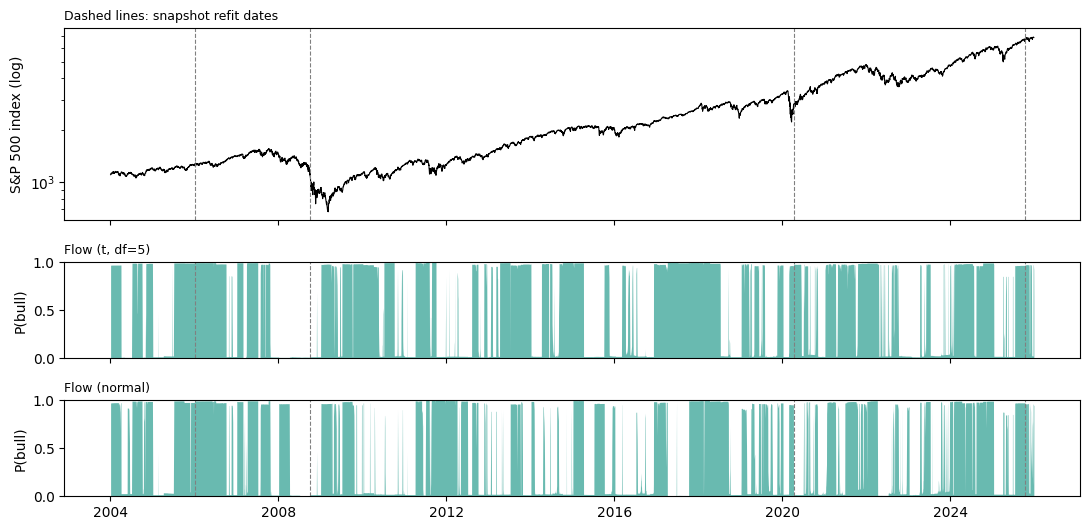

In [3]:
fig, axes = plt.subplots(len(runs) + 1, 1, figsize=(11, 2.4 + 1.5 * len(runs)),
                         sharex=True,
                         gridspec_kw={"height_ratios": [2] + [1] * len(runs)})
span = prices.loc[reference.date.min():reference.date.max()]
axes[0].plot(span.index, span, color="black", linewidth=0.8)
axes[0].set(yscale="log", ylabel="S&P 500 index (log)")
for ax, (name, run) in zip(axes[1:], runs.items()):
    s = run["signals"]
    ax.fill_between(s.date, s.bull_probability, color=COLORS["bull"],
                    alpha=0.7, linewidth=0)
    ax.set(ylim=(0, 1), ylabel="P(bull)")
    ax.set_title(name, fontsize=9, loc="left")
for ax in axes:
    for date in KEY_DATES.values():
        ax.axvline(date, color="grey", linestyle="--", linewidth=0.8)
axes[0].set_title("Dashed lines: snapshot refit dates", fontsize=9, loc="left")
fig.tight_layout()
plt.show()

## What PC1 is: top-8 feature loadings (same PCA for both flows)

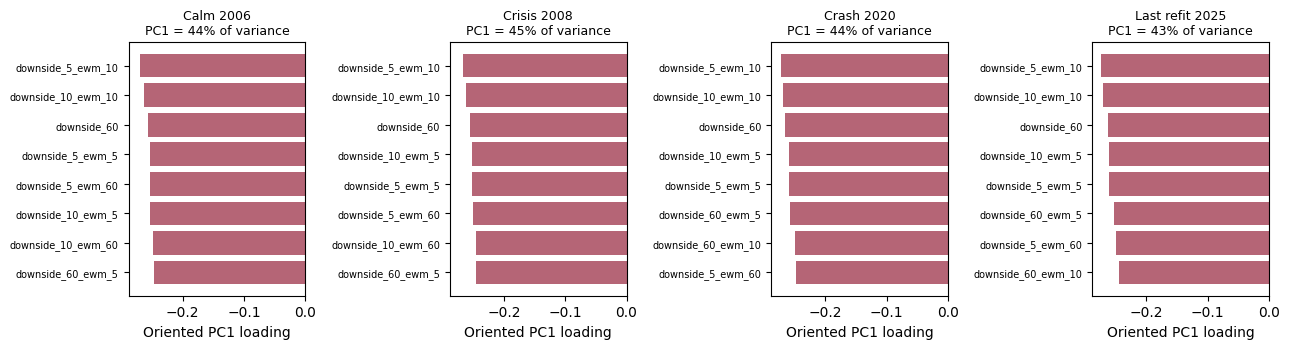

In [4]:
first = next(iter(runs))
fig, axes = plt.subplots(1, len(KEY_DATES), figsize=(13, 3.6), sharex=True)
for ax, label in zip(axes, KEY_DATES):
    snap = snaps[(first, label)]
    names = np.asarray(snap["scaler"].feature_names_in_)
    loading = signs[(first, label)] * snap["pca"].components_[0]
    top = np.argsort(np.abs(loading))[-8:]
    ax.barh(names[top], loading[top],
            color=np.where(loading[top] > 0, "#457b9d", "#b56576"))
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_title(f"{label}\nPC1 = {100 * snap['pca'].explained_variance_ratio_[0]:.0f}%"
                 " of variance", fontsize=9)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("Oriented PC1 loading")
fig.tight_layout()
plt.show()

## Base densities: Student-t (df = 5) vs normal, unit variance

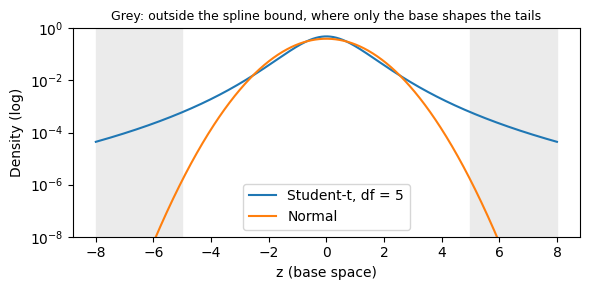

In [5]:
z = np.linspace(-8, 8, 801)
fig, ax = plt.subplots(figsize=(6, 3))
for label, base in (("Student-t, df = 5", SimpleNamespace(base_distribution="student_t", base_df=5.0)),
                    ("Normal", SimpleNamespace(base_distribution="normal", base_df=5.0))):
    ax.plot(z, np.exp(fsp.base_log_prob(base, z)), label=label)
ax.axvspan(-8, -5, color="0.92")
ax.axvspan(5, 8, color="0.92")
ax.set(yscale="log", ylim=(1e-8, 1), xlabel="z (base space)", ylabel="Density (log)",
       title="Grey: outside the spline bound, where only the base shapes the tails")
ax.title.set_fontsize(9)
ax.legend()
fig.tight_layout()
plt.show()

## Learned PC1 spline map $z = S(u)$ and its slope, per state

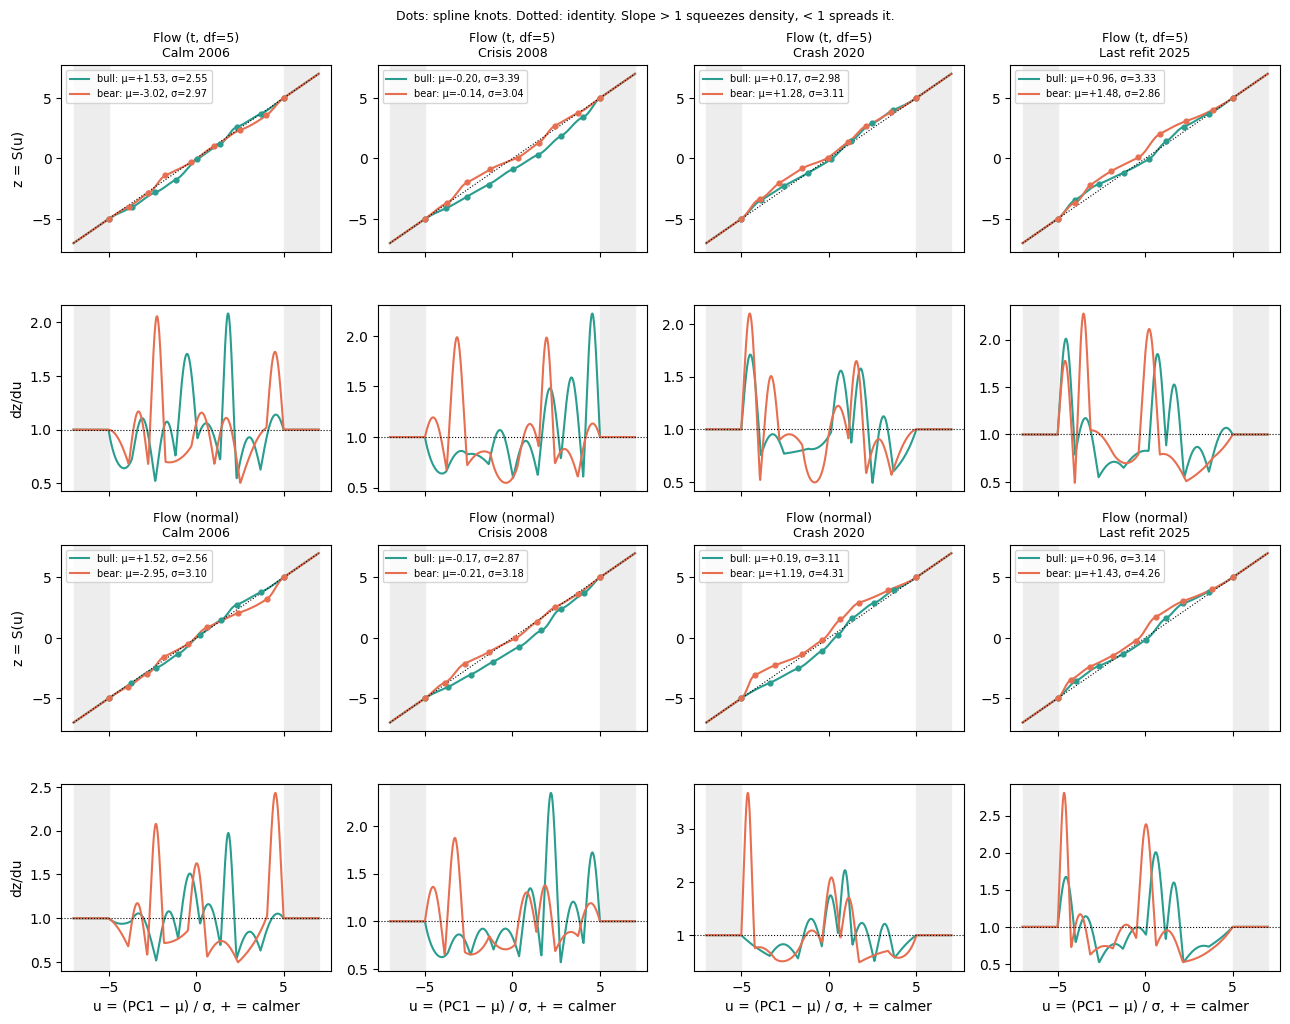

In [6]:
u_grid = np.linspace(-7, 7, 701)
fig, axes = plt.subplots(2 * len(runs), len(KEY_DATES),
                         figsize=(13, 2.6 * 2 * len(runs)), sharex=True)
for row, name in enumerate(runs):
    for col, label in enumerate(KEY_DATES):
        snap, sign = snaps[(name, label)], signs[(name, label)]
        top, bottom = axes[2 * row, col], axes[2 * row + 1, col]
        for k, state in state_names(snap).items():
            probe = fsp.pc1_flow(snap["model"], k, [0.0], sign)
            grid = probe["location"] + probe["scale"] * u_grid
            r = fsp.pc1_flow(snap["model"], k, grid, sign)
            color = COLORS[state]
            top.plot(r["u"], r["z"], color=color,
                     label=f"{state}: μ={r['location']:+.2f}, σ={r['scale']:.2f}")
            top.scatter(r["knots_u"], r["knots_z"], color=color, s=12, zorder=3)
            bottom.plot(r["u"], r["slope"], color=color)
        for ax in (top, bottom):
            ax.axvspan(-7, -r["bound"], color="0.93")
            ax.axvspan(r["bound"], 7, color="0.93")
        top.plot([-7, 7], [-7, 7], color="black", linestyle=":", linewidth=0.8)
        bottom.axhline(1, color="black", linestyle=":", linewidth=0.8)
        top.set_title(f"{name}\n{label}", fontsize=9)
        top.legend(fontsize=7, loc="upper left")
        if col == 0:
            top.set_ylabel("z = S(u)")
            bottom.set_ylabel("dz/du")
        if row == len(runs) - 1:
            bottom.set_xlabel("u = (PC1 − μ) / σ, + = calmer")
fig.suptitle("Dots: spline knots. Dotted: identity. Slope > 1 squeezes density, "
             "< 1 spreads it.", fontsize=9)
fig.tight_layout()
plt.show()

## PC1 density per state: exact model marginal vs posterior-weighted data

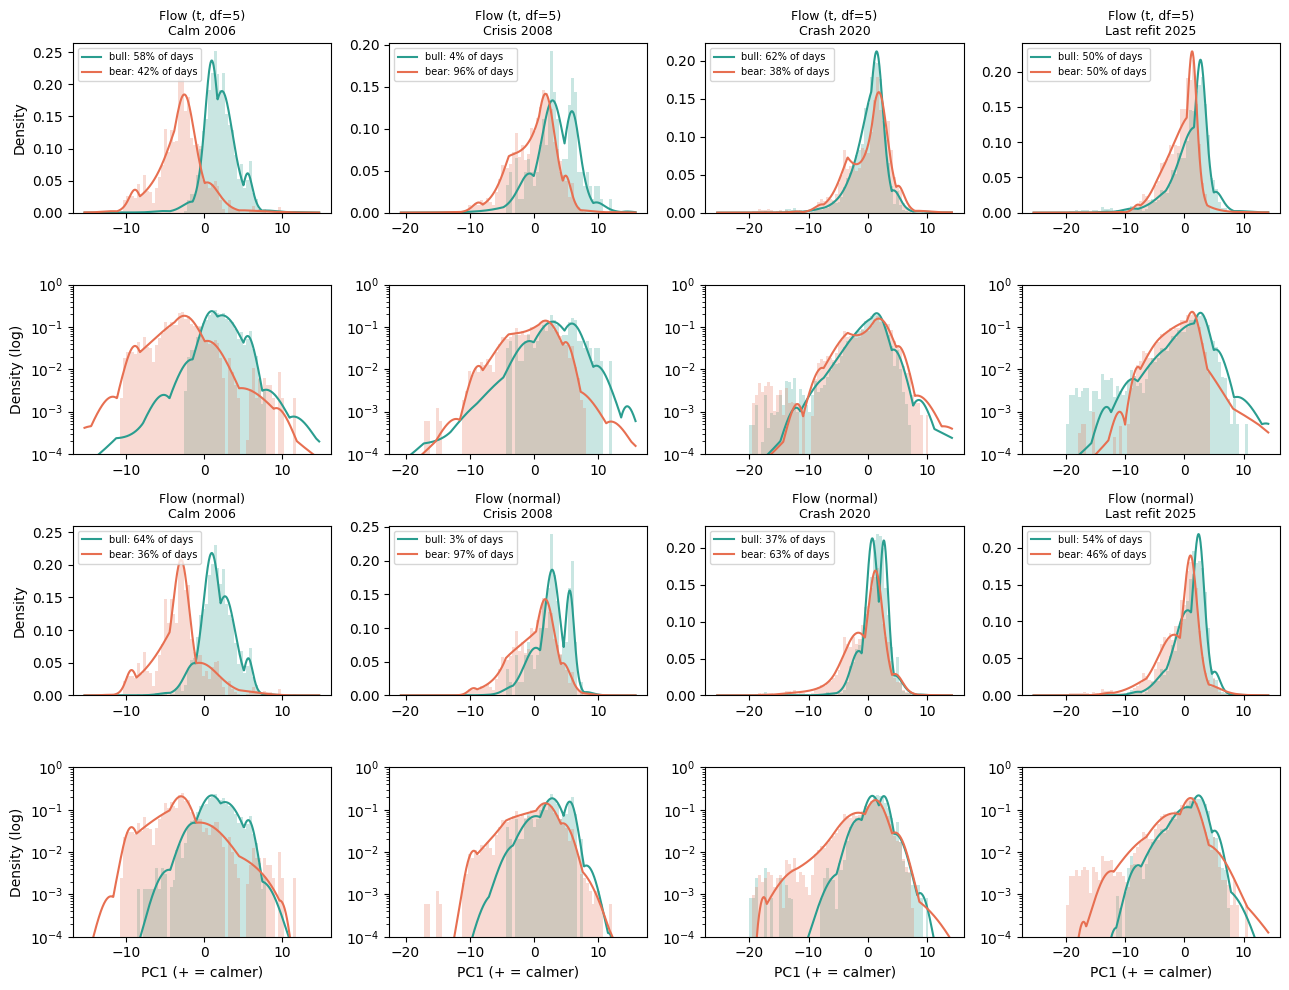

In [7]:
fig, axes = plt.subplots(2 * len(runs), len(KEY_DATES),
                         figsize=(13, 2.5 * 2 * len(runs)))
for row, name in enumerate(runs):
    for col, label in enumerate(KEY_DATES):
        snap, sign = snaps[(name, label)], signs[(name, label)]
        grid = pc1_grid(snap, sign)
        x = sign * snap["X"][:, 0]
        linear, log = axes[2 * row, col], axes[2 * row + 1, col]
        for k, state in state_names(snap).items():
            density = np.exp(fsp.pc1_flow(snap["model"], k, grid, sign)["log_density"])
            weight = snap["smoothed"][:, k]
            for ax in (linear, log):
                ax.hist(x, bins=80, range=(grid[0], grid[-1]), weights=weight,
                        density=True, color=COLORS[state], alpha=0.25)
                ax.plot(grid, density, color=COLORS[state], linewidth=1.5,
                        label=f"{state}: {weight.mean():.0%} of days")
        log.set(yscale="log", ylim=(1e-4, 1))
        linear.set_title(f"{name}\n{label}", fontsize=9)
        linear.legend(fontsize=7)
        if col == 0:
            linear.set_ylabel("Density")
            log.set_ylabel("Density (log)")
        if row == len(runs) - 1:
            log.set_xlabel("PC1 (+ = calmer)")
fig.tight_layout()
plt.show()

## Same-day return density per state: model draws vs posterior-weighted data

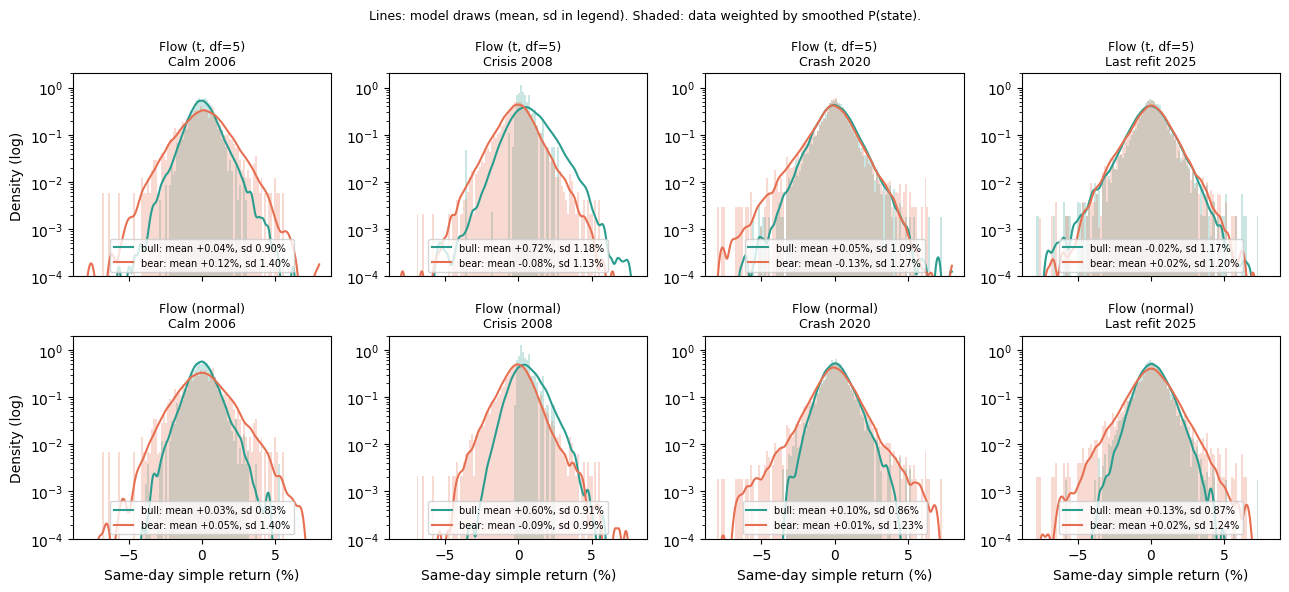

Sampled return densities in 11s


In [8]:
started = time.monotonic()
return_grid = np.linspace(-8, 8, 801)
fig, axes = plt.subplots(len(runs), len(KEY_DATES), figsize=(13, 3.0 * len(runs)),
                         sharex=True, squeeze=False)
for row, name in enumerate(runs):
    for col, label in enumerate(KEY_DATES):
        snap, ax = snaps[(name, label)], axes[row, col]
        observed = fsp.reconstructed_returns(snap)
        for k, state in state_names(snap).items():
            draws = fsp.return_samples(snap, k, N_SAMPLES, SEED)
            weight = snap["smoothed"][:, k]
            ax.hist(observed, bins=120, range=(-8, 8), weights=weight, density=True,
                    color=COLORS[state], alpha=0.25)
            ax.plot(return_grid, gaussian_kde(draws)(return_grid), color=COLORS[state],
                    linewidth=1.5,
                    label=f"{state}: mean {draws.mean():+.2f}%, sd {draws.std():.2f}%")
        ax.set(yscale="log", ylim=(1e-4, 2))
        ax.set_title(f"{name}\n{label}", fontsize=9)
        ax.legend(fontsize=7, loc="lower center")
        if col == 0:
            ax.set_ylabel("Density (log)")
        if row == len(runs) - 1:
            ax.set_xlabel("Same-day simple return (%)")
fig.suptitle("Lines: model draws (mean, sd in legend). Shaded: data weighted by "
             "smoothed P(state).", fontsize=9)
fig.tight_layout()
plt.show()
print(f"Sampled return densities in {time.monotonic() - started:.0f}s")

## Next-day return by saved forecast (the return the strategy trades)

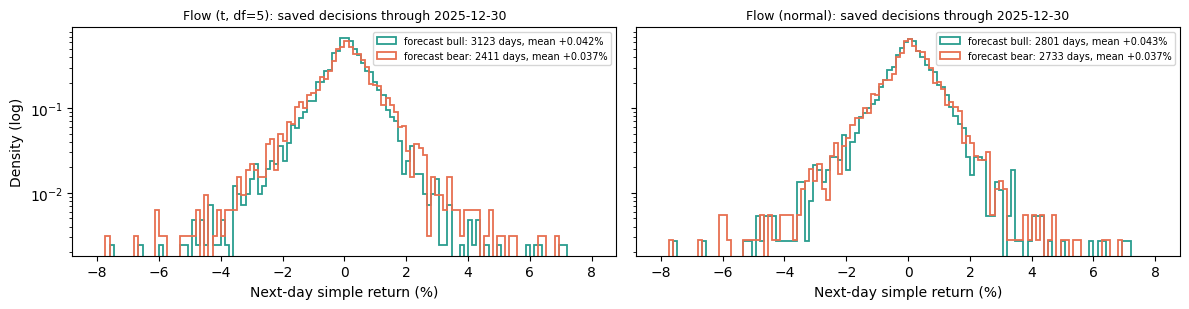

In [9]:
next_return = 100 * prices.pct_change(fill_method=None).shift(-1)
fig, axes = plt.subplots(1, len(runs), figsize=(6 * len(runs), 3.2), sharey=True,
                         squeeze=False)
for ax, (name, run) in zip(axes[0], runs.items()):
    s = run["signals"].set_index("date")
    r = next_return.reindex(s.index)
    for state, mask in (("bull", s.bull_raw.eq(1)), ("bear", s.bull_raw.eq(0))):
        ax.hist(r[mask], bins=120, range=(-8, 8), density=True, histtype="step",
                color=COLORS[state], linewidth=1.3,
                label=f"forecast {state}: {mask.sum()} days, mean {r[mask].mean():+.3f}%")
    ax.set(yscale="log", xlabel="Next-day simple return (%)",
           title=f"{name}: saved decisions through {s.index.max().date()}")
    ax.title.set_fontsize(9)
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel("Density (log)")
fig.tight_layout()
plt.show()

## Where each flow splits bull from bear: PC1 vs same-day return

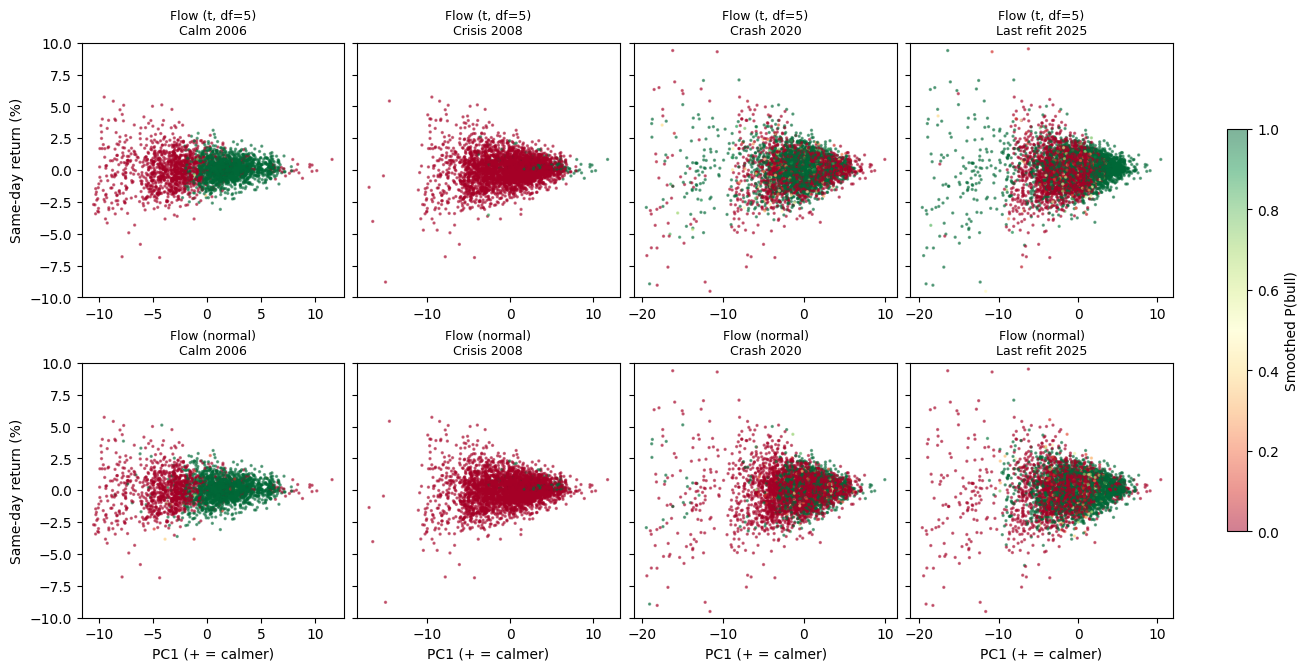

In [10]:
fig, axes = plt.subplots(len(runs), len(KEY_DATES), figsize=(13, 3.3 * len(runs)),
                         sharey=True, squeeze=False, layout="constrained")
for row, name in enumerate(runs):
    for col, label in enumerate(KEY_DATES):
        snap, sign, ax = snaps[(name, label)], signs[(name, label)], axes[row, col]
        points = ax.scatter(sign * snap["X"][:, 0], 100 * snap["returns"],
                            c=snap["smoothed"][:, snap["bull"]], cmap="RdYlGn",
                            vmin=0, vmax=1, s=2, alpha=0.5, rasterized=True)
        ax.set(ylim=(-10, 10))
        ax.set_title(f"{name}\n{label}", fontsize=9)
        if col == 0:
            ax.set_ylabel("Same-day return (%)")
        if row == len(runs) - 1:
            ax.set_xlabel("PC1 (+ = calmer)")
fig.colorbar(points, ax=axes, shrink=0.7, label="Smoothed P(bull)")
plt.show()

## How EM learns the states: 2008-10-03 refit, iteration by iteration

Cache /home/bomb/project/FlexibleEmissionHMM/notebooks/sp500/results/flow_replay_cache: 2 reused, 0 to compute
Flow (t, df=5): final snapshot P(bull) 0.016766 vs refit replay 0.016766
Flow (normal): final snapshot P(bull) 0.016366 vs refit replay 0.016366
EM snapshots in 0s


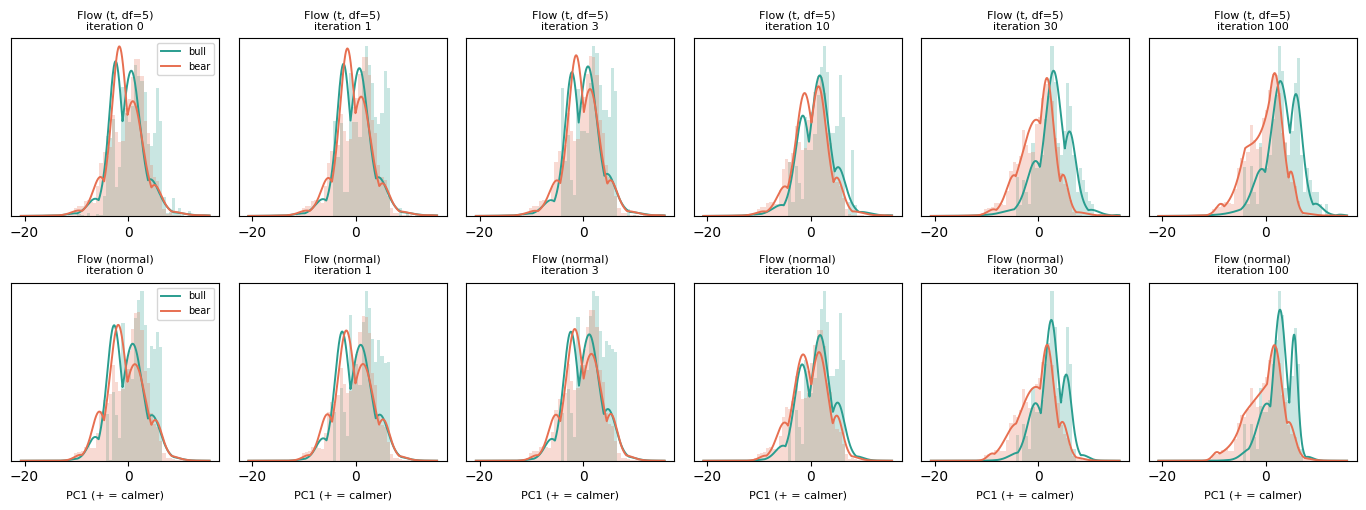

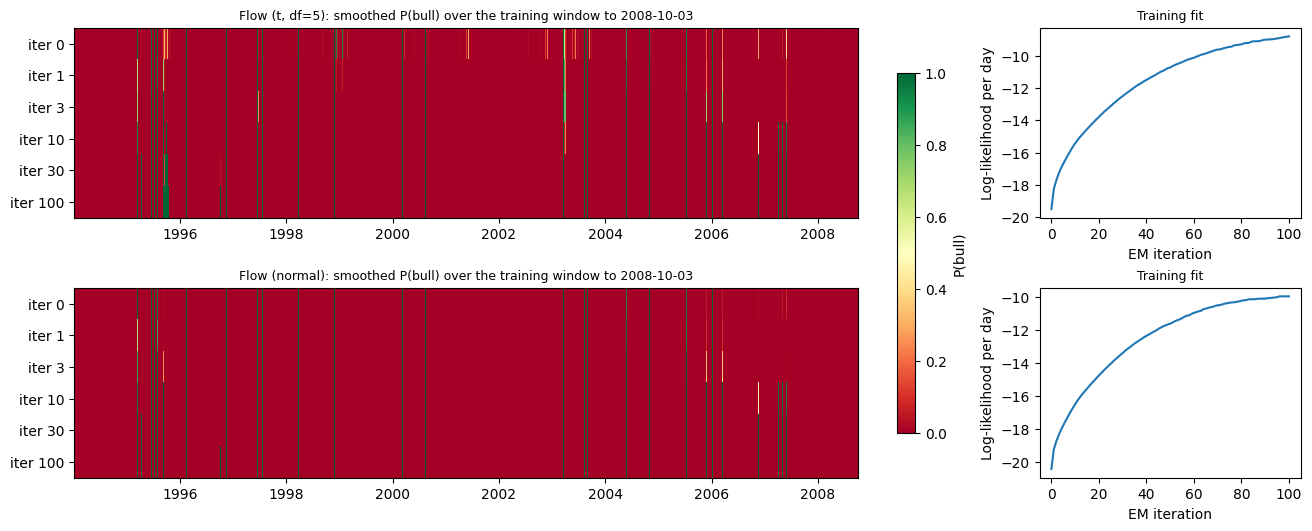

In [11]:
started = time.monotonic()
EM_DATE = KEY_DATES["Crisis 2008"]
totals = {}
for name, run in runs.items():
    saved = run["signals"].set_index("date")
    totals[name] = (int(saved.loc[EM_DATE, "iterations"]) if EM_DATE in saved.index
                    else int(run["settings"]["max_iter"]))
em = fsp.run_jobs({name: (fsp.em_snapshots, run["settings"], EM_DATE, totals[name])
                   for name, run in runs.items()}, workers=WORKERS, threads=THREADS,
                  cache=CACHE)
for name, (steps, _) in em.items():
    final = steps[totals[name]]["next_bull"]
    print(f"{name}: final snapshot P(bull) {final:.6f} vs refit replay "
          f"{snaps[(name, 'Crisis 2008')]['next_bull']:.6f}")
print(f"EM snapshots in {time.monotonic() - started:.0f}s")

n_cols = max(len(steps) for steps, _ in em.values())
fig, axes = plt.subplots(len(runs), n_cols, figsize=(2.3 * n_cols, 2.6 * len(runs)),
                         squeeze=False)
for row, (name, (steps, _)) in enumerate(em.items()):
    final = steps[totals[name]]
    names = state_names(final)  # State identity is fixed through EM.
    sign = signs[(name, "Crisis 2008")]
    grid = pc1_grid(final, sign)
    x = sign * final["X"][:, 0]
    for col, (iteration, snap) in enumerate(steps.items()):
        ax = axes[row, col]
        for k, state in names.items():
            density = np.exp(fsp.pc1_flow(snap["model"], k, grid, sign)["log_density"])
            ax.hist(x, bins=60, range=(grid[0], grid[-1]), weights=snap["smoothed"][:, k],
                    density=True, color=COLORS[state], alpha=0.25)
            ax.plot(grid, density, color=COLORS[state], linewidth=1.4, label=state)
        ax.set_title(f"{name}\niteration {iteration}", fontsize=8)
        ax.set_yticks([])
        if row == len(runs) - 1:
            ax.set_xlabel("PC1 (+ = calmer)", fontsize=8)
    axes[row, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(len(runs), 2, figsize=(13, 2.6 * len(runs)), squeeze=False,
                         layout="constrained",
                         gridspec_kw={"width_ratios": [3, 1]})
for row, (name, (steps, log_likelihood)) in enumerate(em.items()):
    bull = steps[totals[name]]["bull"]
    dates = steps[0]["dates"]
    path = np.vstack([snap["smoothed"][:, bull] for snap in steps.values()])
    image = axes[row, 0].imshow(
        path, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest",
        extent=(mdates.date2num(dates[0]), mdates.date2num(dates[-1]), len(steps) - 0.5, -0.5))
    axes[row, 0].xaxis_date()
    axes[row, 0].set_yticks(range(len(steps)), [f"iter {i}" for i in steps])
    axes[row, 0].set_title(f"{name}: smoothed P(bull) over the training window to "
                           f"{EM_DATE.date()}")
    n_days = len(steps[0]["X"])
    axes[row, 1].plot(np.arange(len(log_likelihood)), log_likelihood / n_days)
    axes[row, 1].set(xlabel="EM iteration", ylabel="Log-likelihood per day",
                     title="Training fit")
    for ax in axes[row]:
        ax.title.set_fontsize(9)
fig.colorbar(image, ax=axes[:, 0], shrink=0.8, label="P(bull)")
plt.show()

## State persistence at each snapshot

In [12]:
rows = []
for (name, label), snap in snaps.items():
    P, b = snap["model"].transmat_, snap["bull"]
    rows.append({"model": name, "snapshot": label,
                 "P(stay bull)": P[b, b], "P(stay bear)": P[1 - b, 1 - b],
                 "bull days implied": 1 / (1 - P[b, b]),
                 "bear days implied": 1 / (1 - P[1 - b, 1 - b]),
                 "share of days bull": snap["smoothed"][:, b].mean()})
display(pd.DataFrame(rows).set_index(["model", "snapshot"]).round(3))

P(stay bull)  P(stay bear)  bull days implied  \
model          snapshot                                                         
Flow (t, df=5) Calm 2006               0.996         0.994            249.571   
               Crisis 2008             0.562         0.983              2.281   
               Crash 2020              0.981         0.968             52.243   
               Last refit 2025         0.974         0.974             37.990   
Flow (normal)  Calm 2006               0.993         0.987            138.257   
               Crisis 2008             0.464         0.984              1.864   
               Crash 2020              0.969         0.982             32.609   
               Last refit 2025         0.961         0.953             25.819   

                                bear days implied  share of days bull  
model          snapshot                                                
Flow (t, df=5) Calm 2006                  178.894               0.582  
               Crisis 2008                 59.645               0.037  
               Crash 2020                  31.048               0.623  
               Last refit 2025             37.758               0.498  
Flow (normal)  Calm 2006                   76.662               0.644  
               Crisis 2008                 61.104               0.030  
               Crash 2020                  56.200               0.372  
               Last refit 2025             21.356               0.542